# The 11-class stretch target — which skin lesion is it?

**Task.** The primary target of the course project is `diagnosis_1` (Benign / Indeterminate / Malignant).
The stretch target asks for the *specific* diagnosis: one of **11 classes**, from the most common
(basal cell carcinoma, 48 % of lesions) to the rarest (other malignant, 9 lesions in the whole dataset).
A dermatologist needs the second answer to plan treatment; a triage tool needs only the first.

**What this notebook does**

1. Reuses everything already built: the lesion-level splits (no lesion in two splits), the cached hand-crafted features, the
   cost-aware evaluation habits from Session 3.
2. Re-runs the Session 5 comparison (7 feature sets × 6 models, cross-validated on the training split only) for 11 classes.
3. Tests the one new decision this target forces — **how hard to up-weight rare classes** — instead of assuming it.
4. Adds one extension beyond the course so far: **frozen ResNet-18 embeddings**, to see whether the low score is a ceiling of
   hand-crafted features or of the data.
5. Scores each finalist on the test split **once**, with bootstrap intervals, then reads the result per class, per confusion,
   and back at the clinical benign / malignant question.

| Decision | Choice | Why |
|---|---|---|
| Unit of analysis | one row per **lesion** | a lesion has two photographs; the splits are lesion-disjoint (Session 3) |
| Splits | `artifacts/splits/{train,val,test}.csv`, seed 42 | identical to the 3-class work, so the results are comparable |
| Headline metric | **macro-F1 over the 10 evaluable classes** | accuracy rewards predicting BCC for everything (48 %); MAL_OTH has 2 test lesions and is reported, never averaged in |
| Selection | mean 5-fold CV macro-F1 on **train** | the validation split has 1 – 8 lesions in six classes, far too few to choose a model on |
| Imbalance | class weights, strength chosen by CV (§3) | resampling could touch validation data; weights cannot |
| Uncertainty | bootstrap over test lesions | with 7 test lesions in four classes a point estimate is an anecdote |

In [1]:
# --- setup: find the repo root from wherever the notebook is opened -----------
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "milk10k").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import milk10k as mk
from milk10k import features as F

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import torch
from PIL import Image

from milk10k import embeddings as E, mlp
from milk10k import multiclass as mc
from milk10k.data import CLASS_NAMES, MALIGNANT

SEED = mk.config.SEED
CLASSES = mc.CLASSES
BLUE, ORANGE, AQUA = mk.BLUE, mk.ORANGE, mk.AQUA
OUT = mk.config.ARTIFACT_DIR / "eleven_class"
FIGS = ROOT / "reports" / "figures"
OUT.mkdir(parents=True, exist_ok=True); FIGS.mkdir(parents=True, exist_ok=True)
SCORER = {"macro_f1": make_scorer(mc.macro_f1), "balanced_acc": "balanced_accuracy"}
RESULTS = {"seed": SEED}                    # every headline number lands here -> scores.json

## 1. The target, class by class

`dx` has 11 values. Every class is wholly benign or wholly malignant, which matters later: P(malignant) is just the sum of
the malignant columns, so an 11-class model can still answer the triage question.

In [2]:
frames = F.load_lesion_splits()
meta = F.metadata_features(frames)                          # categories + median from TRAIN only
ids = pd.concat([f[c] for f in frames.values() for c in ("derm_id", "clinical_id")])
feats = F.feature_table(ids, cache=F.FEATURE_DIR / "features.npz")      # 33 hand-crafted numbers per image (+4 HSV)
y = {k: v["dx"].to_numpy() for k, v in frames.items()}

support = pd.DataFrame({k: pd.Series(v).value_counts() for k, v in y.items()}).reindex(CLASSES).fillna(0).astype(int)
support.insert(0, "malignant", ["yes" if c in MALIGNANT else "no" for c in CLASSES])
support.insert(0, "name", [CLASS_NAMES[c] for c in CLASSES])
support["total"] = support[["train", "val", "test"]].sum(axis=1)
support.loc["all"] = ["", "", *support[["train", "val", "test", "total"]].sum()]
support.to_csv(OUT / "class_support.csv")
print(f"{len(frames['train'])} train / {len(frames['val'])} val / {len(frames['test'])} test lesions;  "
      f"smallest test class: {support.loc[CLASSES, 'test'].min()} lesions;  imbalance "
      f"{support.loc[CLASSES, 'train'].max() / support.loc[CLASSES, 'train'].min():.0f}:1 in train")
support

3742 train / 749 val / 749 test lesions;  smallest test class: 2 lesions;  imbalance 300:1 in train


,name,malignant,train,val,test,total
AKIEC,Actinic keratosis / intraepidermal carcinoma,yes,217,43,43,303
BCC,Basal cell carcinoma,yes,1802,360,360,2522
BEN_OTH,Other benign proliferations,no,32,6,6,44
BKL,Benign keratinocytic lesion,no,388,78,78,544
DF,Dermatofibroma,no,37,8,7,52
INF,Inflammatory / infectious,no,36,7,7,50
MAL_OTH,Other malignant proliferations,yes,6,1,2,9
MEL,Melanoma,yes,320,65,65,450
NV,Melanocytic nevus,no,532,107,107,746
SCCKA,Squamous cell carcinoma / keratoacanthoma,yes,339,67,67,473


Six classes have fewer than ten lesions in the **validation** split and four have 7 or fewer in **test**. Two consequences run
through the whole notebook: any per-class number for those classes is wide, and any macro-F1 difference of a few hundredths
between two models is noise. The intervals below say so quantitatively rather than leaving it to a caveat.

## 2. Feature sets × models (hand-crafted features)

Same grid as Session 5 — 7 feature sets × 6 models behind a `StandardScaler` in one `Pipeline` — with the headline metric of
this notebook. Each cell is **5-fold stratified CV macro-F1 on the training lesions**; the test split is not touched.
Models that support it use `class_weight="balanced"`; §3 questions that choice.

42 configurations in 118 s


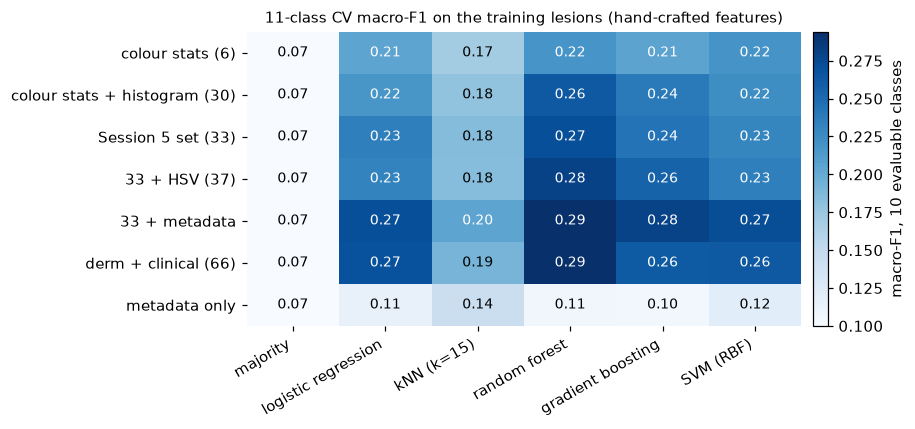

top 5 by CV macro-F1:


,feature set,model,cv_f1,cv_std,cv_bal_acc,val_f1
33,derm + clinical (66),random forest,0.294,0.020,0.309,0.293
27,33 + metadata,random forest,0.293,0.015,0.308,0.315
21,33 + HSV (37),random forest,0.280,0.034,0.301,0.294
28,33 + metadata,gradient boosting,0.280,0.020,0.244,0.286
29,33 + metadata,SVM (RBF),0.272,0.011,0.317,0.283


In [3]:
MODELS = {
    "majority":            lambda: DummyClassifier(strategy="most_frequent"),
    "logistic regression": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
    "kNN (k=15)":          lambda: KNeighborsClassifier(n_neighbors=15),
    "random forest":       lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                      class_weight="balanced", n_jobs=1, random_state=SEED),
    "gradient boosting":   lambda: HistGradientBoostingClassifier(learning_rate=0.1, max_iter=100,
                                      class_weight="balanced", random_state=SEED),
    "SVM (RBF)":           lambda: SVC(class_weight="balanced"),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def pipeline(model_name):
    return Pipeline([("scale", StandardScaler()), ("model", MODELS[model_name]())])

X = {name: {k: F.build_matrix(name, frames[k], feats, meta[k]) for k in frames} for name in F.FEATURE_SETS}

t0 = time.perf_counter()
rows = []
for fs in F.FEATURE_SETS:
    for m in MODELS:
        res = cross_validate(pipeline(m), X[fs]["train"], y["train"], cv=cv, scoring=SCORER, n_jobs=5)
        fitted = pipeline(m).fit(X[fs]["train"], y["train"])
        rows.append({"feature set": fs, "model": m,
                     "cv_f1": res["test_macro_f1"].mean(), "cv_std": res["test_macro_f1"].std(),
                     "cv_bal_acc": res["test_balanced_acc"].mean(),
                     "val_f1": mc.macro_f1(y["val"], fitted.predict(X[fs]["val"]))})
grid = pd.DataFrame(rows)
grid.to_csv(OUT / "feature_model_grid.csv", index=False)
print(f"{len(grid)} configurations in {time.perf_counter() - t0:.0f} s")

pivot = grid.pivot(index="feature set", columns="model", values="cv_f1").loc[list(F.FEATURE_SETS), list(MODELS)]
fig, ax = plt.subplots(figsize=(8.4, 4.0))
im = ax.imshow(pivot.to_numpy(), cmap="Blues", vmin=0.1, vmax=pivot.to_numpy().max(), aspect="auto")
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=30, ha="right")
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.5 * (0.1 + pivot.to_numpy().max()) else "black")
ax.set_title("11-class CV macro-F1 on the training lesions (hand-crafted features)", fontsize=10)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="macro-F1, 10 evaluable classes")
fig.tight_layout(); fig.savefig(FIGS / "ec_model_grid.png", dpi=160, bbox_inches="tight"); plt.show()

best = grid[grid["model"] != "majority"].sort_values("cv_f1", ascending=False)
print("top 5 by CV macro-F1:")
best.head(5).round(3)

In [4]:
top = best.iloc[0]
runner_up = best[best["model"] != top["model"]].iloc[0]
print(f"best: {top['model']} on '{top['feature set']}'  CV {top['cv_f1']:.3f} ± {top['cv_std']:.3f}")
print(f"best of a different model family: {runner_up['model']} on '{runner_up['feature set']}'  CV {runner_up['cv_f1']:.3f}")
print(f"majority-class floor: CV {grid[grid['model'] == 'majority']['cv_f1'].max():.3f}")
BEST_FS = top["feature set"]; BEST_MODEL = top["model"]
RESULTS["grid"] = {"best_model": BEST_MODEL, "best_feature_set": BEST_FS,
                   "best_cv_macro_f1": float(top["cv_f1"]), "best_cv_std": float(top["cv_std"]),
                   "majority_cv_macro_f1": float(grid[grid["model"] == "majority"]["cv_f1"].max())}

best: random forest on 'derm + clinical (66)'  CV 0.294 ± 0.020
best of a different model family: gradient boosting on '33 + metadata'  CV 0.280
majority-class floor: CV 0.065


## 3. How hard should rare classes be up-weighted?

With a 300 : 1 imbalance, sklearn's `"balanced"` rule gives MAL_OTH a weight above 100 and BCC a weight near 0.2. That is a
strong claim, made by default. `mc.power_weights(y, p)` turns it into a dial: weight = (N / (K · n_c))<sup>p</sup>, with
p = 0 (no weighting), 0.5 (square root) and 1 (full inverse frequency). The forest is refit at each setting on the best
feature set and scored by the same 5-fold CV. Balanced accuracy is shown beside macro-F1 because it is the
mean recall — the "did we find them" view that weighting is meant to improve.

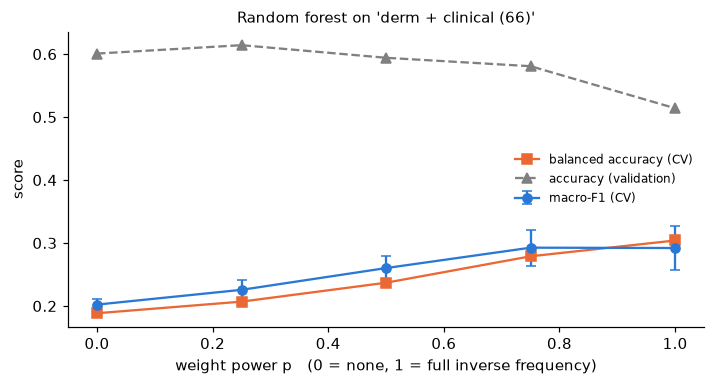

CV picks p = 0.75


,power,cv_f1,cv_std,cv_bal_acc,val_f1,val_accuracy
0,0.00,0.202,0.009,0.188,0.204,0.601
1,0.25,0.226,0.015,0.207,0.238,0.614
2,0.50,0.260,0.020,0.237,0.304,0.594
3,0.75,0.293,0.029,0.279,0.308,0.581
4,1.00,0.292,0.034,0.304,0.293,0.514


In [5]:
def forest(weights, **kw):
    params = dict(n_estimators=300, min_samples_leaf=3, class_weight=weights, n_jobs=1, random_state=SEED)
    return Pipeline([("scale", StandardScaler()), ("model", RandomForestClassifier(**{**params, **kw}))])

rows = []
for p in (0.0, 0.25, 0.5, 0.75, 1.0):
    w = mc.power_weights(y["train"], p)
    res = cross_validate(forest(w), X[BEST_FS]["train"], y["train"], cv=cv, scoring=SCORER, n_jobs=5)
    fitted = forest(w).fit(X[BEST_FS]["train"], y["train"])
    pred = fitted.predict(X[BEST_FS]["val"])
    rows.append({"power": p, "cv_f1": res["test_macro_f1"].mean(), "cv_std": res["test_macro_f1"].std(),
                 "cv_bal_acc": res["test_balanced_acc"].mean(),
                 "val_f1": mc.macro_f1(y["val"], pred),
                 "val_accuracy": float((pred == y["val"]).mean())})
wtab = pd.DataFrame(rows)
wtab.to_csv(OUT / "weight_power.csv", index=False)

fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.errorbar(wtab["power"], wtab["cv_f1"], yerr=wtab["cv_std"], marker="o", color=BLUE, capsize=3, label="macro-F1 (CV)")
ax.plot(wtab["power"], wtab["cv_bal_acc"], marker="s", color=ORANGE, label="balanced accuracy (CV)")
ax.plot(wtab["power"], wtab["val_accuracy"], marker="^", color="grey", ls="--", label="accuracy (validation)")
ax.set_xlabel("weight power p   (0 = none, 1 = full inverse frequency)"); ax.set_ylabel("score")
ax.set_title(f"Random forest on '{BEST_FS}'", fontsize=10); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "ec_class_weights.png", dpi=160); plt.show()

BEST_P = float(wtab.sort_values("cv_f1", ascending=False).iloc[0]["power"])
print(f"CV picks p = {BEST_P}")
RESULTS["weight_power"] = {"chosen": BEST_P, "table": wtab.round(4).to_dict("records")}
wtab.round(3)

The weight is the lever that trades **accuracy against recall on rare classes**: more weight finds more of the rare
lesions but mislabels more of the common ones. The fold-to-fold spread (error bars) is as large as the differences between
neighbouring settings, so the choice is made by CV mean as pre-registered, not because one setting is clearly better.

## 4. Tuning the hand-crafted finalist

A small grid search on the forest (`min_samples_leaf`, `max_features`) at the chosen weight power, 5-fold CV on train only.

In [6]:
search = GridSearchCV(forest(mc.power_weights(y["train"], BEST_P)),
                      {"model__min_samples_leaf": [1, 3, 5, 10], "model__max_features": ["sqrt", 0.3]},
                      scoring=SCORER["macro_f1"], cv=cv, n_jobs=5).fit(X[BEST_FS]["train"], y["train"])
hand = search.best_estimator_
assert list(hand.classes_) == CLASSES
print(f"tuned forest: CV {search.best_score_:.3f}   {search.best_params_}")
print(f"validation macro-F1 (check, not used to choose): "
      f"{mc.macro_f1(y['val'], hand.predict(X[BEST_FS]['val'])):.3f}")
RESULTS["hand_crafted_finalist"] = {"feature_set": BEST_FS, "weight_power": BEST_P,
        "params": {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in search.best_params_.items()},
        "cv_macro_f1": float(search.best_score_)}

tuned forest: CV 0.305   {'model__max_features': 0.3, 'model__min_samples_leaf': 5}
validation macro-F1 (check, not used to choose): 0.338


## 5. Extension: frozen ResNet-18 embeddings

The 33 hand-crafted numbers measure colour and texture. A convolutional network pretrained on ImageNet describes an image
with 512 numbers learned to separate a thousand everyday object classes. It has never seen a skin lesion, and **nothing is
trained here except the small logistic-regression head on top** — no gradient reaches the network, so the lesion-level
splits and the train-only rule still hold. Embedding extraction is cached (`artifacts/features/resnet18_embeddings.npz`,
about a minute for all 10,480 images).

Question: is the weak 11-class score a ceiling of hand-crafted features, or of the data?

In [7]:
t0 = time.perf_counter()
emb = E.resnet18_embeddings(ids)
print(f"embeddings {emb.shape} ({time.perf_counter() - t0:.0f} s, device: {E._device()})")

def lr_head(C):
    return Pipeline([("scale", StandardScaler()),
                     ("model", LogisticRegression(C=C, max_iter=3000, class_weight=mc.power_weights(y["train"], BEST_P)))])

rows = []
for views in (("derm",), ("derm", "clinical")):
    Xv = E.embedding_matrix(frames["train"], emb, views)
    for C in (0.0003, 0.001, 0.003, 0.01, 0.03, 0.1):
        res = cross_validate(lr_head(C), Xv, y["train"], cv=cv, scoring=SCORER, n_jobs=5)
        rows.append({"views": "+".join(views), "C": C, "cv_f1": res["test_macro_f1"].mean(),
                     "cv_std": res["test_macro_f1"].std(), "cv_bal_acc": res["test_balanced_acc"].mean()})
etab = pd.DataFrame(rows)
etab.to_csv(OUT / "embedding_logreg_grid.csv", index=False)
ebest = etab.sort_values("cv_f1", ascending=False).iloc[0]
EMB_VIEWS = tuple(ebest["views"].split("+")); EMB_C = float(ebest["C"])
print(f"best: views={EMB_VIEWS}  C={EMB_C}  CV {ebest['cv_f1']:.3f} ± {ebest['cv_std']:.3f}   "
      f"(hand-crafted forest: CV {search.best_score_:.3f})")
etab.pivot(index="C", columns="views", values="cv_f1").round(3)

embeddings (10480, 512) (0 s, device: mps)


best: views=('derm', 'clinical')  C=0.001  CV 0.408 ± 0.028   (hand-crafted forest: CV 0.305)


views,derm,derm+clinical
C,,
0.0003,0.322,0.387
0.0010,0.358,0.408
0.0030,0.372,0.404
0.0100,0.374,0.402
0.0300,0.366,0.386
0.1000,0.343,0.369


In [8]:
XE = {k: E.embedding_matrix(frames[k], emb, EMB_VIEWS) for k in frames}
deep = lr_head(EMB_C).fit(XE["train"], y["train"])
assert list(deep.classes_) == CLASSES
print(f"ResNet-18 + logistic regression: validation macro-F1 {mc.macro_f1(y['val'], deep.predict(XE['val'])):.3f} "
      f"(forest on hand-crafted: {mc.macro_f1(y['val'], hand.predict(X[BEST_FS]['val'])):.3f})")
RESULTS["embedding_finalist"] = {"views": list(EMB_VIEWS), "C": EMB_C, "weight_power": BEST_P,
                                 "cv_macro_f1": float(ebest["cv_f1"]), "cv_std": float(ebest["cv_std"])}

ResNet-18 + logistic regression: validation macro-F1 0.392 (forest on hand-crafted: 0.338)


## 6. A small neural network, as in Session 6

The Session 6 recipe (`milk10k.mlp`: Adam, class-weighted cross-entropy, seeded initialisation) with 11 outputs. The number of
epochs is read from the **validation loss** curve (the validation F1 is too noisy with 1 – 8 lesions in six classes), then
the network is retrained from scratch for exactly that many epochs on the training split. Two inputs are tried: the 66
hand-crafted features and the 1,024 embedding values.

MLP, 66 hand-crafted         validation loss is lowest after 22 epochs


MLP, ResNet-18 embeddings    validation loss is lowest after  7 epochs


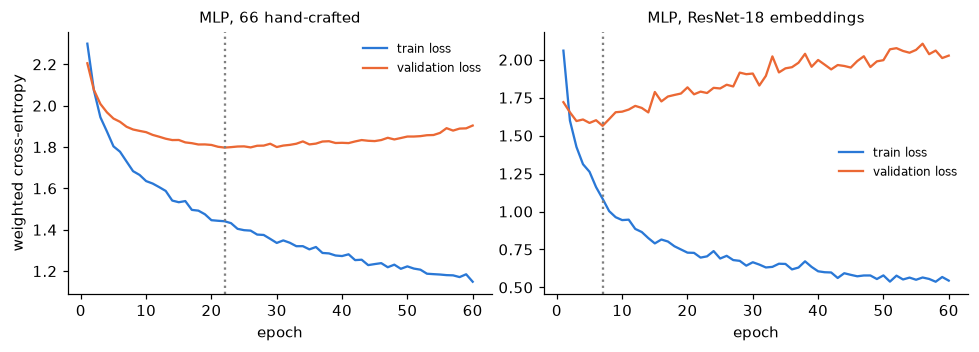

In [9]:
def run_mlp(Xtr, ytr, Xva, yva, n_in, hidden=(64,), dropout=0.0, weight_decay=0.0, epochs=80, lr=1e-3, p=BEST_P):
    scaler = StandardScaler().fit(Xtr)
    A, B = mlp.to_tensor(scaler.transform(Xtr)), mlp.to_tensor(scaler.transform(Xva))
    a, b = torch.tensor(mc.encode(ytr)), torch.tensor(mc.encode(yva))
    w = torch.tensor([mc.power_weights(ytr, p)[c] for c in CLASSES], dtype=torch.float32)
    net = mlp.make_mlp(n_in, hidden, dropout, n_out=11, seed=SEED)
    hist = mlp.fit(net, A, a, B, b, class_weights=w, epochs=epochs, lr=lr, weight_decay=weight_decay, seed=SEED)
    return net, scaler, hist

Xh = X["derm + clinical (66)"]
XEm = XE
specs = {"MLP, 66 hand-crafted": (Xh, Xh["train"].shape[1], dict(hidden=(64,), dropout=0.2, weight_decay=1e-3, epochs=60)),
         "MLP, ResNet-18 embeddings": (XEm, XEm["train"].shape[1], dict(hidden=(64,), dropout=0.5, weight_decay=1e-2, epochs=60))}
curves, nets = {}, {}
for name, (Xs, n_in, kw) in specs.items():
    net, sc, hist = run_mlp(Xs["train"], y["train"], Xs["val"], y["val"], n_in, **kw)
    curves[name] = hist
    stop = int(hist["val_loss"].idxmin()) + 1                       # epochs, counting from 1
    net, sc, _ = run_mlp(Xs["train"], y["train"], Xs["val"], y["val"], n_in, **{**kw, "epochs": stop})
    nets[name] = (net, sc, stop)
    print(f"{name:28s} validation loss is lowest after {stop:2d} epochs")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharey=False)
for ax, (name, h) in zip(axes, curves.items()):
    ax.plot(h.index + 1, h["train_loss"], color=BLUE, label="train loss")
    ax.plot(h.index + 1, h["val_loss"], color=ORANGE, label="validation loss")
    ax.axvline(nets[name][2], color="grey", ls=":"); ax.set_title(name, fontsize=10)
    ax.set_xlabel("epoch"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("weighted cross-entropy")
fig.tight_layout(); fig.savefig(FIGS / "ec_mlp_curves.png", dpi=160); plt.show()

In [10]:
def mlp_proba(name, Xs, split):
    net, sc, _ = nets[name]
    net.eval()
    with torch.no_grad():
        return torch.softmax(net(mlp.to_tensor(sc.transform(Xs[split]))), dim=1).numpy()

for name, (Xs, *_ ) in specs.items():
    pv = np.array(CLASSES)[mlp_proba(name, Xs, "val").argmax(1)]
    print(f"{name:28s} validation macro-F1 {mc.macro_f1(y['val'], pv):.3f}")

MLP, 66 hand-crafted         validation macro-F1 0.297
MLP, ResNet-18 embeddings    validation macro-F1 0.385


## 7. The one-shot test score

Everything is now fixed. The finalists were chosen **without** the test split:

* **Headline model** = whichever of the two classical finalists (hand-crafted forest, ResNet-18 + logistic regression) has the
  higher CV macro-F1 on train.
* The other classical finalist, both MLPs and the dummy baselines are reported next to it so the comparison is visible, but none of
  them is chosen on the test result.

Each model is scored exactly once on the 749 test lesions, with a 95 % bootstrap interval for macro-F1.

In [11]:
finalists = {"hand-crafted forest": (hand, X[BEST_FS], search.best_score_),
             "ResNet-18 + logistic regression": (deep, XE, ebest["cv_f1"])}
HEADLINE = max(finalists, key=lambda k: finalists[k][2])
print(f"headline model (highest CV): {HEADLINE}")

test_pred, test_proba, val_proba = {}, {}, {}
test_pred["majority class (BCC)"] = np.full(len(y["test"]), "BCC")
test_pred["stratified random"] = DummyClassifier(strategy="stratified", random_state=SEED).fit(
    np.zeros((len(y["train"]), 1)), y["train"]).predict(np.zeros((len(y["test"]), 1)))
for name, (model, Xs, _) in finalists.items():
    test_proba[name], val_proba[name] = model.predict_proba(Xs["test"]), model.predict_proba(Xs["val"])
    test_pred[name] = np.array(CLASSES)[test_proba[name].argmax(1)]
for name, (Xs, *_ ) in specs.items():
    test_proba[name], val_proba[name] = mlp_proba(name, Xs, "test"), mlp_proba(name, Xs, "val")
    test_pred[name] = np.array(CLASSES)[test_proba[name].argmax(1)]

rows = []
for name, pred in test_pred.items():
    s = mc.summary_scores(y["test"], pred, test_proba.get(name))
    lo, hi = mc.bootstrap_ci(y["test"], pred, n_boot=2000, seed=SEED)
    rows.append({"model": name, **s, "macro_f1_lo": lo, "macro_f1_hi": hi, "headline": name == HEADLINE})
final = pd.DataFrame(rows).set_index("model")
final.to_csv(OUT / "final_table.csv")
show = final.copy()
show["macro-F1 (10 classes)"] = [f"{r.macro_f1:.3f}  [{r.macro_f1_lo:.3f}, {r.macro_f1_hi:.3f}]" for r in show.itertuples()]
show = show.rename(columns={"macro_f1_all11": "macro-F1 (all 11)", "balanced_accuracy": "balanced acc.",
                            "top3_accuracy": "top-3 acc."})
show[["macro-F1 (10 classes)", "macro-F1 (all 11)", "balanced acc.", "accuracy", "top-3 acc."]].round(3)

headline model (highest CV): ResNet-18 + logistic regression


,macro-F1 (10 classes),macro-F1 (all 11),balanced acc.,accuracy,top-3 acc.
model,,,,,
majority class (BCC),"0.065 [0.062, 0.068]",0.059,0.091,0.481,NaN
stratified random,"0.105 [0.089, 0.123]",0.095,0.096,0.284,NaN
hand-crafted forest,"0.281 [0.232, 0.328]",0.256,0.265,0.546,0.845
ResNet-18 + logistic regression,"0.423 [0.353, 0.479]",0.385,0.434,0.591,0.866
"MLP, 66 hand-crafted","0.295 [0.245, 0.340]",0.268,0.320,0.498,0.813
"MLP, ResNet-18 embeddings","0.458 [0.390, 0.516]",0.417,0.506,0.599,0.876


In [12]:
RESULTS["test"] = json.loads(final.round(4).to_json(orient="index"))        # NaN -> null
RESULTS["headline_model"] = HEADLINE
h = final.loc[HEADLINE]
print(f"{HEADLINE}: test macro-F1 {h.macro_f1:.3f} (95 % CI {h.macro_f1_lo:.3f} – {h.macro_f1_hi:.3f}), "
      f"balanced accuracy {h.balanced_accuracy:.3f}, top-3 accuracy {h.top3_accuracy:.3f}")
print(f"majority class: macro-F1 {final.loc['majority class (BCC)', 'macro_f1']:.3f}, "
      f"accuracy {final.loc['majority class (BCC)', 'accuracy']:.3f}")

ResNet-18 + logistic regression: test macro-F1 0.423 (95 % CI 0.353 – 0.479), balanced accuracy 0.434, top-3 accuracy 0.866
majority class: macro-F1 0.065, accuracy 0.481


## 8. Class by class

A single macro-F1 hides the story. Below, F1 per class with a bootstrap interval, next to the number of training lesions the
model had to learn the class from.

In [13]:
y_hat = test_pred[HEADLINE]; P = test_proba[HEADLINE]
rep = mc.per_class_f1_ci(y["test"], y_hat, n_boot=1000, seed=SEED)
rep.insert(0, "n_train", support.loc[CLASSES, "train"].to_numpy())
rep.insert(0, "name", [CLASS_NAMES[c] for c in CLASSES])
rep.to_csv(OUT / "per_class_test.csv")
rep.round(3)

,name,n_train,precision,recall,f1,support,f1_lo,f1_hi
AKIEC,Actinic keratosis / intraepidermal carcinoma,217,0.265,0.302,0.283,43,0.158,0.404
BCC,Basal cell carcinoma,1802,0.788,0.714,0.749,360,0.716,0.786
BEN_OTH,Other benign proliferations,32,0.143,0.333,0.200,6,0.000,0.421
BKL,Benign keratinocytic lesion,388,0.390,0.205,0.269,78,0.162,0.371
DF,Dermatofibroma,37,0.286,0.571,0.381,7,0.095,0.636
INF,Inflammatory / infectious,36,0.188,0.429,0.261,7,0.000,0.500
MAL_OTH,Other malignant proliferations,6,0.000,0.000,0.000,2,0.000,0.000
MEL,Melanoma,320,0.419,0.477,0.446,65,0.338,0.544
NV,Melanocytic nevus,532,0.676,0.645,0.660,107,0.582,0.731
SCCKA,Squamous cell carcinoma / keratoacanthoma,339,0.429,0.672,0.523,67,0.436,0.610


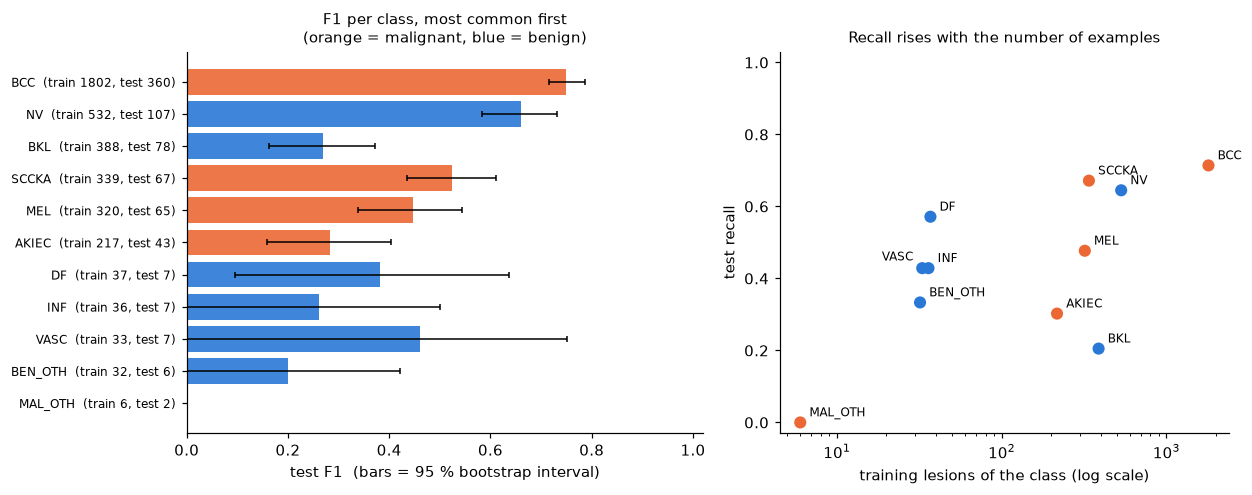

In [14]:
order = rep.sort_values("n_train", ascending=False).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
r = rep.loc[order][::-1]
colors = [ORANGE if c in MALIGNANT else BLUE for c in r.index]
ax.barh(range(len(r)), r["f1"], color=colors, alpha=0.9)
ax.errorbar(r["f1"], range(len(r)), xerr=[r["f1"] - r["f1_lo"], r["f1_hi"] - r["f1"]], fmt="none", ecolor="black", capsize=2, lw=1)
ax.set_yticks(range(len(r)), [f"{c}  (train {n}, test {s})" for c, n, s in zip(r.index, r["n_train"], r["support"])], fontsize=8)
ax.set_xlim(0, 1.02); ax.set_xlabel("test F1  (bars = 95 % bootstrap interval)")
ax.set_title("F1 per class, most common first\n(orange = malignant, blue = benign)", fontsize=10)
ax = axes[1]
ax.scatter(rep["n_train"], rep["recall"], c=[ORANGE if c in MALIGNANT else BLUE for c in rep.index], s=48, zorder=3)
LEFT = {"VASC"}                                   # VASC and INF sit on top of each other
for c, row in rep.iterrows():
    ax.annotate(c, (row["n_train"], row["recall"]), textcoords="offset points", fontsize=8,
                xytext=(-6, 5) if c in LEFT else (6, 4), ha="right" if c in LEFT else "left")
ax.set_xscale("log"); ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("training lesions of the class (log scale)"); ax.set_ylabel("test recall")
ax.set_title("Recall rises with the number of examples", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "ec_per_class.png", dpi=160, bbox_inches="tight"); plt.show()

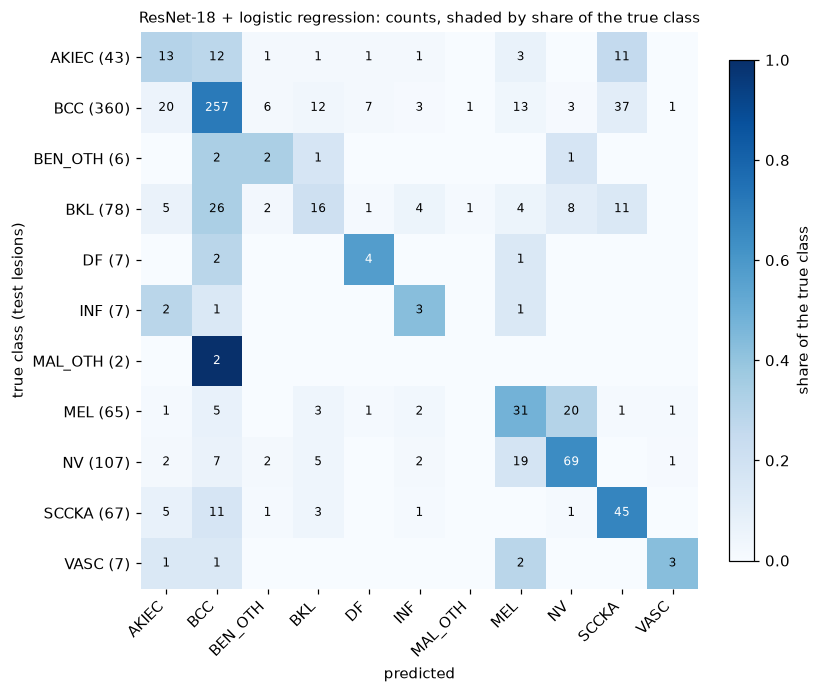

,truth,predicted,n,share_of_true_class
0,BCC,SCCKA,37,0.10
1,BKL,BCC,26,0.33
2,BCC,AKIEC,20,0.06
3,MEL,NV,20,0.31
4,NV,MEL,19,0.18
5,BCC,MEL,13,0.04
6,BCC,BKL,12,0.03
7,AKIEC,BCC,12,0.28


In [15]:
cm = pd.crosstab(pd.Categorical(y["test"], CLASSES), pd.Categorical(y_hat, CLASSES), dropna=False)
cm.to_csv(OUT / "confusion_matrix_test.csv")
frac = cm.div(cm.sum(axis=1).replace(0, 1), axis=0).to_numpy()
fig, ax = plt.subplots(figsize=(7.4, 6.4))
im = ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(11), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(11), [f"{c} ({n})" for c, n in zip(CLASSES, cm.sum(axis=1))])
for i in range(11):
    for j in range(11):
        if cm.iat[i, j]:
            ax.text(j, i, cm.iat[i, j], ha="center", va="center", fontsize=8, color="white" if frac[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true class (test lesions)")
ax.set_title(f"{HEADLINE}: counts, shaded by share of the true class", fontsize=10)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, label="share of the true class")
fig.tight_layout(); fig.savefig(FIGS / "ec_confusion_matrix.png", dpi=160, bbox_inches="tight"); plt.show()

conf = mc.top_confusions(y["test"], y_hat, top=8)
conf["share_of_true_class"] = conf["share_of_true_class"].round(2)
conf.to_csv(OUT / "top_confusions.csv", index=False)
conf

### The most confident mistakes

The eight test lesions on which the model was most sure and wrong — dermoscopic image, with the model's probability for its (wrong)
answer. Looking at them is a sanity check that the errors are the kind a human might also make, not an artefact such as a ruler,
a hair or a border.

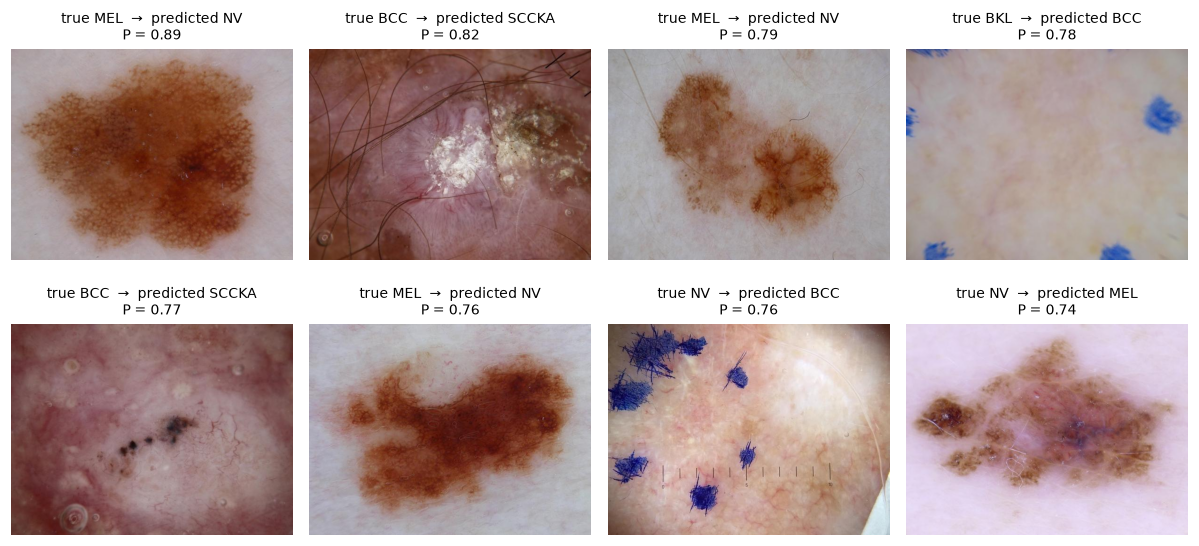

In [16]:
wrong = np.where(y_hat != y["test"])[0]
conf_wrong = wrong[np.argsort(-P[wrong, [CLASSES.index(p) for p in y_hat[wrong]]])][:8]
fig, axes = plt.subplots(2, 4, figsize=(11, 5.4))
for ax, i in zip(axes.ravel(), conf_wrong):
    with Image.open(mk.IMAGE_DIR / f"{frames['test'].loc[i, 'derm_id']}.jpg") as im_:
        ax.imshow(im_.convert("RGB"))
    p_pred = P[i, CLASSES.index(y_hat[i])]
    ax.set_title(f"true {y['test'][i]}  →  predicted {y_hat[i]}\nP = {p_pred:.2f}", fontsize=9)
    ax.axis("off")
fig.tight_layout(); fig.savefig(FIGS / "ec_confident_mistakes.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Back to the clinical question: benign or malignant?

The 11-class model can still answer the triage question. Because every class is wholly benign or wholly malignant,
P(malignant) is the sum of the five malignant columns. That is compared with the **Session 5 three-class forest** (refit
here with its exact settings), which answers the same question with P(Malignant) + P(Indeterminate) — the collapse rule recorded in
`labels.py`. Cost per lesion uses the course's numbers: a missed malignant lesion costs 50, an unnecessary work-up costs 1.

The decision threshold is 0.5 first, then a **screening threshold chosen on the validation split** to reach 95 % sensitivity.
The test split never sets a threshold.

In [17]:
# Session 5's three-class forest, refit with the settings in artifacts/session05/baseline_scores.json
y3 = {k: v["diagnosis_1"].to_numpy() for k, v in frames.items()}
X66 = X["derm + clinical (66)"]
rf3 = Pipeline([("scale", StandardScaler()),
                ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
                                                 class_weight="balanced", n_jobs=1, random_state=SEED))]
               ).fit(X66["train"], y3["train"])
assert list(rf3.classes_) == ["Benign", "Indeterminate", "Malignant"]
p3 = {s: rf3.predict_proba(X66[s])[:, 1:].sum(axis=1) for s in ("val", "test")}        # P(Indeterminate) + P(Malignant)

scores = {"Session 5 forest (3 classes)": p3,
          "11-class hand-crafted forest": {s: mc.p_malignant(P_) for s, P_ in
                                          (("val", val_proba["hand-crafted forest"]), ("test", test_proba["hand-crafted forest"]))},
          "11-class ResNet-18 + logistic regression": {s: mc.p_malignant(P_) for s, P_ in
                                          (("val", val_proba["ResNet-18 + logistic regression"]), ("test", test_proba["ResNet-18 + logistic regression"]))}}
rows = []
for name, sc in scores.items():
    r05 = mc.binary_report(y["test"], sc["test"], 0.5)
    t95 = mc.threshold_for_sensitivity(y["val"], sc["val"], 0.95)
    r95 = mc.binary_report(y["test"], sc["test"], t95)
    rows.append({"model": name, "AUC": r05["auc"],
                 "sens @0.5": r05["sensitivity"], "spec @0.5": r05["specificity"], "cost @0.5": r05["cost_per_lesion"],
                 "threshold (val, 95 % sens.)": t95,
                 "sens @val-thr": r95["sensitivity"], "spec @val-thr": r95["specificity"], "cost @val-thr": r95["cost_per_lesion"]})
binary = pd.DataFrame(rows).set_index("model")
binary.to_csv(OUT / "binary_comparison.csv")
RESULTS["binary"] = binary.round(4).to_dict("index")
RESULTS["malignant_share_test"] = float(mc.is_malignant(y["test"]).mean())
print(f"{mc.is_malignant(y['test']).mean():.1%} of test lesions are malignant; "
      f"always predicting 'malignant' costs {mc.BINARY_COST.loc['Benign', 'Malignant'] * (1 - mc.is_malignant(y['test']).mean()):.2f} per lesion")
binary.round(3)

71.7% of test lesions are malignant; always predicting 'malignant' costs 0.28 per lesion


,AUC,sens @0.5,spec @0.5,cost @0.5,"threshold (val, 95 % sens.)",sens @val-thr,spec @val-thr,cost @val-thr
model,,,,,,,,
Session 5 forest (3 classes),0.783,0.879,0.552,4.466,0.372,0.944,0.344,2.188
11-class hand-crafted forest,0.745,0.827,0.533,6.340,0.398,0.916,0.316,3.198
11-class ResNet-18 + logistic regression,0.816,0.851,0.599,5.454,0.329,0.953,0.425,1.832


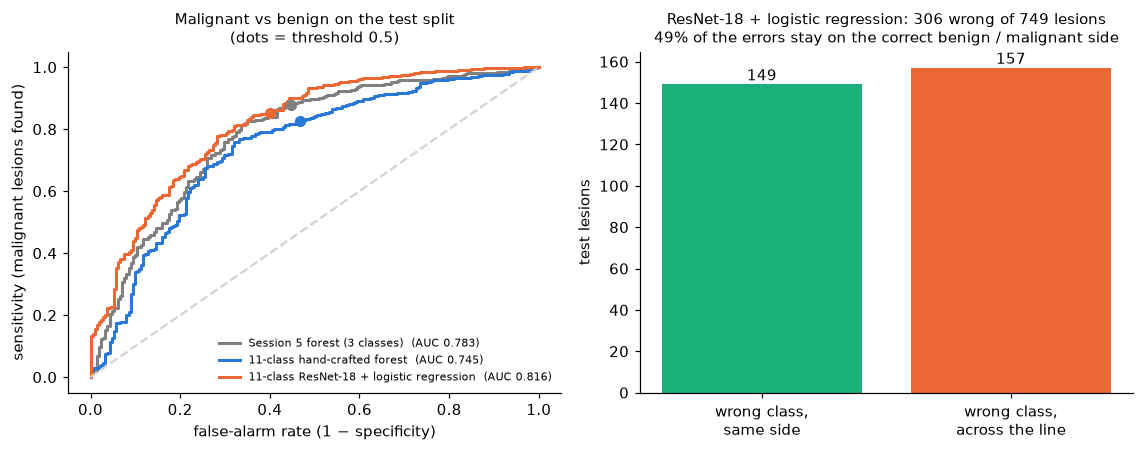

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1, 1]})
truth = mc.is_malignant(y["test"])
palette = {"Session 5 forest (3 classes)": "grey", "11-class hand-crafted forest": BLUE,
           "11-class ResNet-18 + logistic regression": ORANGE}
ax = axes[0]
for name, sc in scores.items():
    fpr, tpr, _ = roc_curve(truth, sc["test"])
    ax.plot(fpr, tpr, color=palette[name], lw=2, label=f"{name}  (AUC {binary.loc[name, 'AUC']:.3f})")
    ax.scatter([1 - binary.loc[name, "spec @0.5"]], [binary.loc[name, "sens @0.5"]], color=palette[name], s=40, zorder=3)
ax.plot([0, 1], [0, 1], color="lightgrey", ls="--"); ax.set_xlabel("false-alarm rate (1 − specificity)")
ax.set_ylabel("sensitivity (malignant lesions found)"); ax.legend(frameon=False, fontsize=7, loc="lower right")
ax.set_title("Malignant vs benign on the test split\n(dots = threshold 0.5)", fontsize=10)

# where do the 11-class errors go: same side of the benign/malignant line, or across it?
wrong_mask = y_hat != y["test"]
across = (mc.is_malignant(y["test"]) != mc.is_malignant(y_hat))[wrong_mask]
share_same = 1 - across.mean()
ax = axes[1]
ax.bar(["wrong class,\nsame side", "wrong class,\nacross the line"], [(~across).sum(), across.sum()], color=[AQUA, ORANGE])
for i, v in enumerate([(~across).sum(), across.sum()]):
    ax.text(i, v + 2, str(v), ha="center", fontsize=10)
ax.set_ylabel("test lesions"); ax.set_title(f"{HEADLINE}: {wrong_mask.sum()} wrong of {len(y_hat)} lesions\n"
                                            f"{share_same:.0%} of the errors stay on the correct benign / malignant side", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "ec_binary.png", dpi=160); plt.show()
RESULTS["errors_same_side_share"] = float(share_same)

In [19]:
with open(OUT / "scores.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("wrote", (OUT / "scores.json").relative_to(ROOT))

wrote artifacts/eleven_class/scores.json


## 10. What this shows, and what it does not

**What the evidence supports**

* **Frozen ResNet-18 features beat the hand-crafted ones by a wide margin.** Test macro-F1 on the ten evaluable classes is
  0.423 [0.353, 0.479] for ResNet-18 + logistic regression against 0.281 [0.232, 0.328] for the best hand-crafted forest; the
  intervals do not overlap, and CV on the training split ordered them the same way (0.408 against 0.305). The majority-class
  baseline scores 0.065 and a stratified random guess 0.105. The low hand-crafted score is a ceiling of the features, not only of
  the data.
* **The model is useful on the common classes and an anecdote on the rare ones.** BCC (F1 0.75), NV (0.66) and SCCKA (0.52) carry
  the average. DF, INF, VASC and BEN_OTH have 6 – 7 test lesions each; their F1 intervals span 0.4 or more, and MAL_OTH (2 test
  lesions) is never found. Recall rises with the number of training lesions, as the right panel of the per-class figure shows.
* **The errors are clinically readable.** The largest confusions are BCC → SCCKA (37), BKL → BCC (26), BCC → AKIEC (20) and
  melanoma ↔ naevus (MEL → NV 20, NV → MEL 19). 31 % of melanomas are called naevi, which is the error that matters most and the
  one a screening threshold has to push down. The most confident mistakes are visually ambiguous lesions, not artefacts.
* **Eleven classes do not cost the triage answer.** Collapsed to benign / malignant, the 11-class ResNet model has AUC 0.816
  against 0.783 for the Session 5 three-class forest. At a screening threshold chosen on validation to reach 95 % sensitivity it
  catches 95.3 % of malignant test lesions, with specificity 0.425 and a cost of 1.83 per lesion (Session 5: 0.944, 0.344, 2.19).
  Almost half of the 306 wrong labels (149) stay on the correct side of the benign / malignant line.

**What it does not show**

* **Not a clinical tool.** 749 test lesions from one dataset, one split, no external validation, no calibration study. The 71.7 %
  malignant share of the test split is far above what a primary-care clinic sees, so specificity here will not carry over.
* **The headline is chosen by a rule, not by the test score.** The MLP on the embeddings scores higher on test (0.458 [0.391,
  0.516], balanced accuracy 0.506) but the rule fixed beforehand picked logistic regression from CV, and the two intervals
  overlap. The MLP is reported, not promoted.
* **Differences of a few hundredths are noise.** With 7 lesions in four classes a single mislabelled lesion moves a class F1 by
  more than 0.1.
* **The embeddings are an extension beyond the course.** The ResNet is used frozen and never trained on skin, so the next
  steps are the obvious ones: fine-tune a CNN with augmentation (Session 7 onward), and use pooled cross-validation over
  train + validation so the rare classes get more than six to eight lesions to learn from.